# Fase 2 — Base de conhecimento
Baixa as fontes oficiais (`base/fontes.yaml`), fatia por artigo/seção (300–500 tokens, sobreposição ~50) e gera a tabela da base.

**Rode todas as células e salve o notebook com as saídas** (o guia exige notebooks com saídas salvas).

In [1]:
import sys, os
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(RAIZ)
sys.path.insert(0, str(RAIZ / "src"))
sys.path.insert(0, str(RAIZ / "scripts"))
print(RAIZ)

.


In [2]:
%run scripts/01_baixar_base.py

ok       ctb: 772 KB (local, acesso 2026-11-08)


ok       lbi: 238 KB (local, acesso 2026-11-08)
ok       sp-lei15442: 56 KB (local, acesso 2026-11-08)
ok       sp-dec59671: 66 KB (local, acesso 2026-11-08)
ok       sp-subpref-calcadas: 185 KB (local, acesso 2026-11-08)
ok       sp-subpref-servicos156: 171 KB (local, acesso 2026-11-08)
ok       sp-cartilha-calcadas: 7663 KB (local, acesso 2026-11-08)
pulando  sp156-calcada-particular (ativo: false)
pulando  sp156-obstaculo (ativo: false)
pulando  sp156-entulho (ativo: false)
pulando  sp156-veiculo-calcada (ativo: false)

Próximo: python scripts/02_fatiar.py


In [3]:
%run scripts/02_fatiar.py

ctb: 18 trechos, tokens mediana 342, máx 519
lbi: 11 trechos, tokens mediana 263, máx 522
sp-lei15442: 11 trechos, tokens mediana 182, máx 377
sp-dec59671: 16 trechos, tokens mediana 328, máx 512
sp-subpref-calcadas: 6 trechos, tokens mediana 436, máx 515
sp-subpref-servicos156: 4 trechos, tokens mediana 512, máx 515


sp-cartilha-calcadas: 16 trechos, tokens mediana 384, máx 523

=== 82 trechos em .\base\trechos.jsonl ===


| Fonte | Formato | Licença | Trechos | Acesso | URL |
|---|---|---|---|---|---|
| Código de Trânsito Brasileiro (Lei nº 9.503/1997) | HTML (lei/decreto) | Ato oficial (Lei 9.610/98, art. 8º, IV) — domínio público | 18 | 2026-11-08 | https://www.planalto.gov.br/ccivil_03/leis/l9503compilado.htm |
| Lei Brasileira de Inclusão da Pessoa com Deficiência (Lei nº 13.146/2015) | HTML (lei/decreto) | Ato oficial (Lei 9.610/98, art. 8º, IV) — domínio público | 11 | 2026-11-08 | https://www.planalto.gov.br/ccivil_03/_ato2015-2018/2015/lei/l13146.htm |
| Lei municipal nº 15.442/2011 (limpeza de imóveis e passeios públicos), com alterações | HTML (lei/decreto) | Ato oficial (Lei 9.610/98, art. 8º, IV) — domínio público | 11 | 2026-11-08 | http://legislacao.prefeitura.sp.gov.br/leis/lei-15442-de-09-de-setembro-de-2011 |
| Decreto municipal nº 59.671/2020 (padronização das calçadas) | HTML (lei/decreto) | Ato oficial (Lei 9.610/98, art. 8º, IV) — domínio público | 16 | 2026-11-08 | http://legislaca

ok: todo trecho_id do gabarito existe na base.

Próximo: python scripts/03_indexar.py


,trechos,tokens_mediana,tokens_max
fonte,,,
ctb,18,342.0,519
lbi,11,263.0,522
sp-cartilha-calcadas,16,384.5,523
sp-dec59671,16,328.5,512
sp-lei15442,11,182.0,377
sp-subpref-calcadas,6,436.0,515
sp-subpref-servicos156,4,511.5,515


<Axes: >

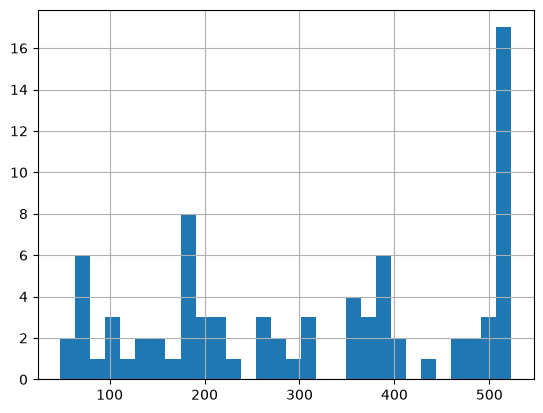

In [4]:
import pandas as pd
from passo_genai.base import carregar_trechos, contar_tokens
df = pd.DataFrame([t.model_dump() for t in carregar_trechos()])
df["tokens"] = df["texto"].map(contar_tokens)
display(df.groupby("fonte").agg(trechos=("trecho_id", "count"), tokens_mediana=("tokens", "median"), tokens_max=("tokens", "max")))
df["tokens"].hist(bins=30)

In [5]:
from IPython.display import Markdown
Markdown(open('base/tabela_base.md', encoding='utf-8').read())

| Fonte | Formato | Licença | Trechos | Acesso | URL |
|---|---|---|---|---|---|
| Código de Trânsito Brasileiro (Lei nº 9.503/1997) | HTML (lei/decreto) | Ato oficial (Lei 9.610/98, art. 8º, IV) — domínio público | 18 | 2026-11-08 | https://www.planalto.gov.br/ccivil_03/leis/l9503compilado.htm |
| Lei Brasileira de Inclusão da Pessoa com Deficiência (Lei nº 13.146/2015) | HTML (lei/decreto) | Ato oficial (Lei 9.610/98, art. 8º, IV) — domínio público | 11 | 2026-11-08 | https://www.planalto.gov.br/ccivil_03/_ato2015-2018/2015/lei/l13146.htm |
| Lei municipal nº 15.442/2011 (limpeza de imóveis e passeios públicos), com alterações | HTML (lei/decreto) | Ato oficial (Lei 9.610/98, art. 8º, IV) — domínio público | 11 | 2026-11-08 | http://legislacao.prefeitura.sp.gov.br/leis/lei-15442-de-09-de-setembro-de-2011 |
| Decreto municipal nº 59.671/2020 (padronização das calçadas) | HTML (lei/decreto) | Ato oficial (Lei 9.610/98, art. 8º, IV) — domínio público | 16 | 2026-11-08 | http://legislacao.prefeitura.sp.gov.br/leis/decreto-59671-de-7-de-agosto-de-2020 |
| Subprefeituras — Calçadas: o direito de ir e vir começa na porta da nossa casa | HTML (página) | Publicação oficial da Prefeitura de São Paulo — conferir termos de uso do portal; citar a fonte | 6 | 2026-11-08 | https://prefeitura.sp.gov.br/subprefeituras/w/noticias/36935 |
| Subprefeituras — Serviços do Portal 156 | HTML (página) | Publicação oficial da Prefeitura de São Paulo — conferir termos de uso do portal; citar a fonte | 4 | 2026-11-08 | https://prefeitura.sp.gov.br/web/subprefeituras/w/pracas_de_atendimento/335674 |
| Cartilha de Calçadas 2023 (SMPED/CPA, Prefeitura de São Paulo) | PDF | Publicação oficial da Prefeitura de São Paulo — conferir termos de uso; citar a fonte | 16 | 2026-11-08 | https://www.prefeitura.sp.gov.br/cidade/secretarias/upload/pessoa_com_deficiencia/2023_08_11%20-%20Livreto%20Cartilha%20de%20Cal%C3%A7adas%202023%20-%20Vrs%20NOVA%20NORMA%20-%20V9.pdf |
| **Total** | | | **82** | | |


In [6]:
print(df.sample(3, random_state=1)['texto'].str[:600].str.cat(sep='\n\n---\n\n'))

Código de Trânsito Brasileiro (Lei nº 9.503/1997) — Art. 71
Art. 71. O órgão ou entidade com circunscrição sobre a via manterá, obrigatoriamente,
as faixas e passagens de pedestres em boas condições de visibilidade, higiene,
segurança e sinalização.
CAPÍTULO V
DO CIDADÃO

---

Cartilha de Calçadas 2023 (SMPED/CPA, Prefeitura de São Paulo) — página 7
 máxima de 8,33% (oito vírgula trinta e três por cento).
 (somente em calçadas com mais de 2,00 m)
3%
3 - faixa de acesso,
des�nada à acomodação
das interferências resultantes 
 da implantação, do uso e da
ocupação das ediﬁcações, 
exclusivamente nas calçadas
com mais de 2,00 m de
largura, que poderá conter:
DICAS!
Quando a inclinação for acentuada, deverá ser promovida texturização para aumentar o atrito.
Não usar pó de cimento para dar acabamento (“cimento queimado”)
Direção do
caminhamento
longitudinalMáximo
Transvers

---

Decreto municipal nº 59.671/2020 (padronização das calçadas) — Art. 20
Art. 20. O mobiliário urbano, bem como os po